In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sounddevice as sd

In [2]:
duration = 5  
sample_rate = 3800  
num_samples = int(duration * sample_rate)

Простой белый шум

[0.60163217 0.77950509 0.07062216 ... 0.0306176  0.39512877 0.85227664]


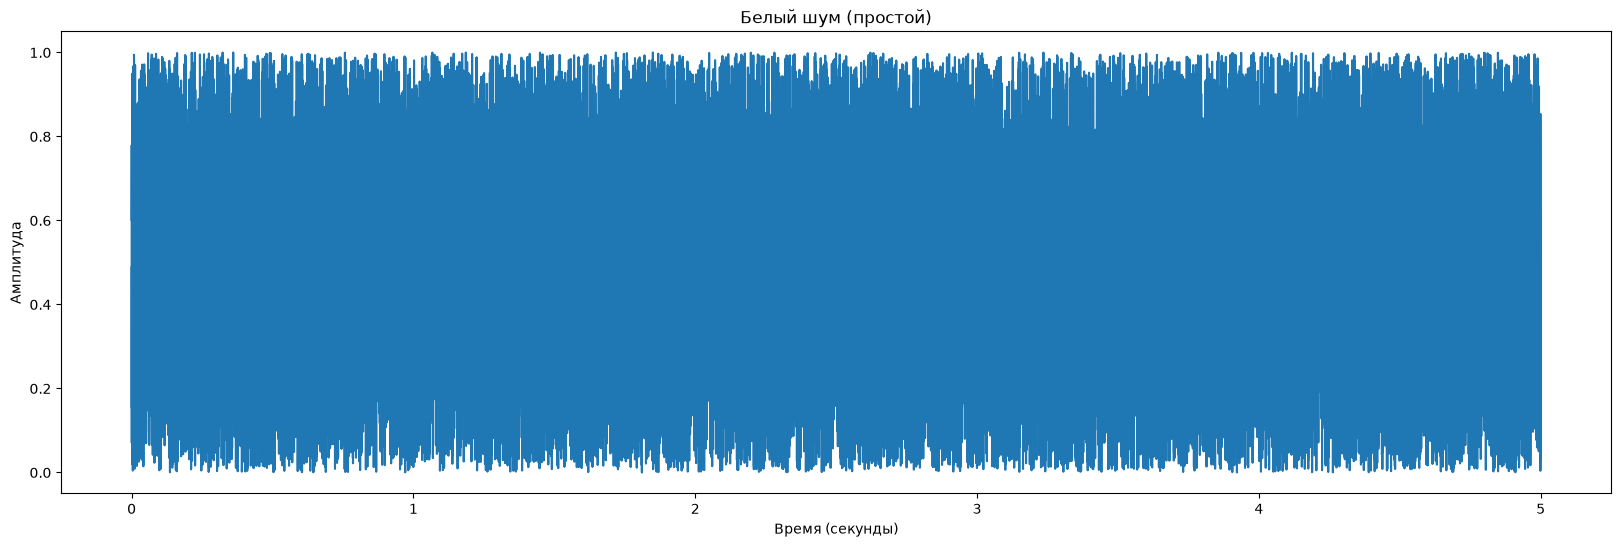

In [3]:
white_noise_simple = np.random.random(num_samples)
print(white_noise_simple)

time_axis = np.linspace(0, duration, len(white_noise_simple)) 

plt.figure(figsize=(20, 6))  

plt.plot(time_axis, white_noise_simple)

plt.title('Белый шум (простой)')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')

plt.show()

In [4]:
sd.play(white_noise_simple, sample_rate)
sd.wait()

Гауссовский белый шум

In [5]:
white_noise_g = np.random.normal(loc = 0, scale = 1, size = num_samples)
print(white_noise_g)  

[-0.58145823 -0.70645434 -0.32375766 ... -0.46740496  0.03509953
  1.00562278]


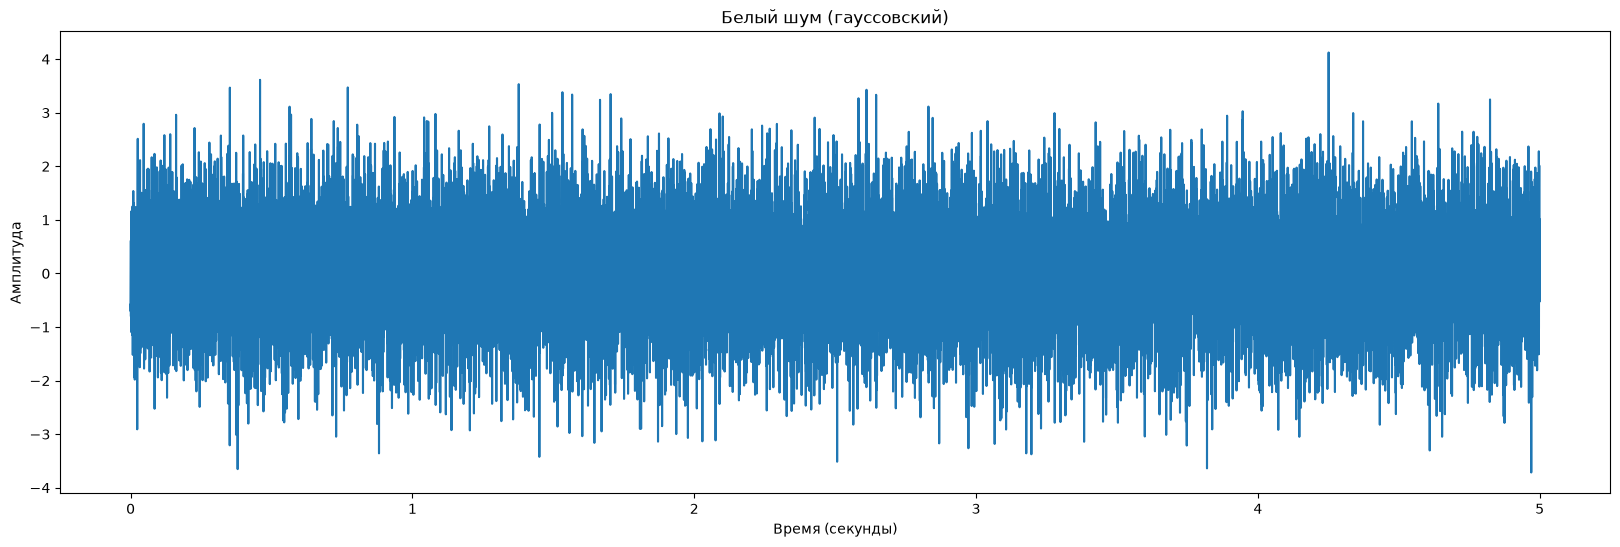

In [6]:
time_axis = np.linspace(0, duration, len(white_noise_g)) 

plt.figure(figsize=(20, 6))  

plt.plot(time_axis, white_noise_g)

plt.title('Белый шум (гауссовский)')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')

plt.show()

In [7]:
sd.play(white_noise_g, sample_rate)
sd.wait()

распределения двух шумов

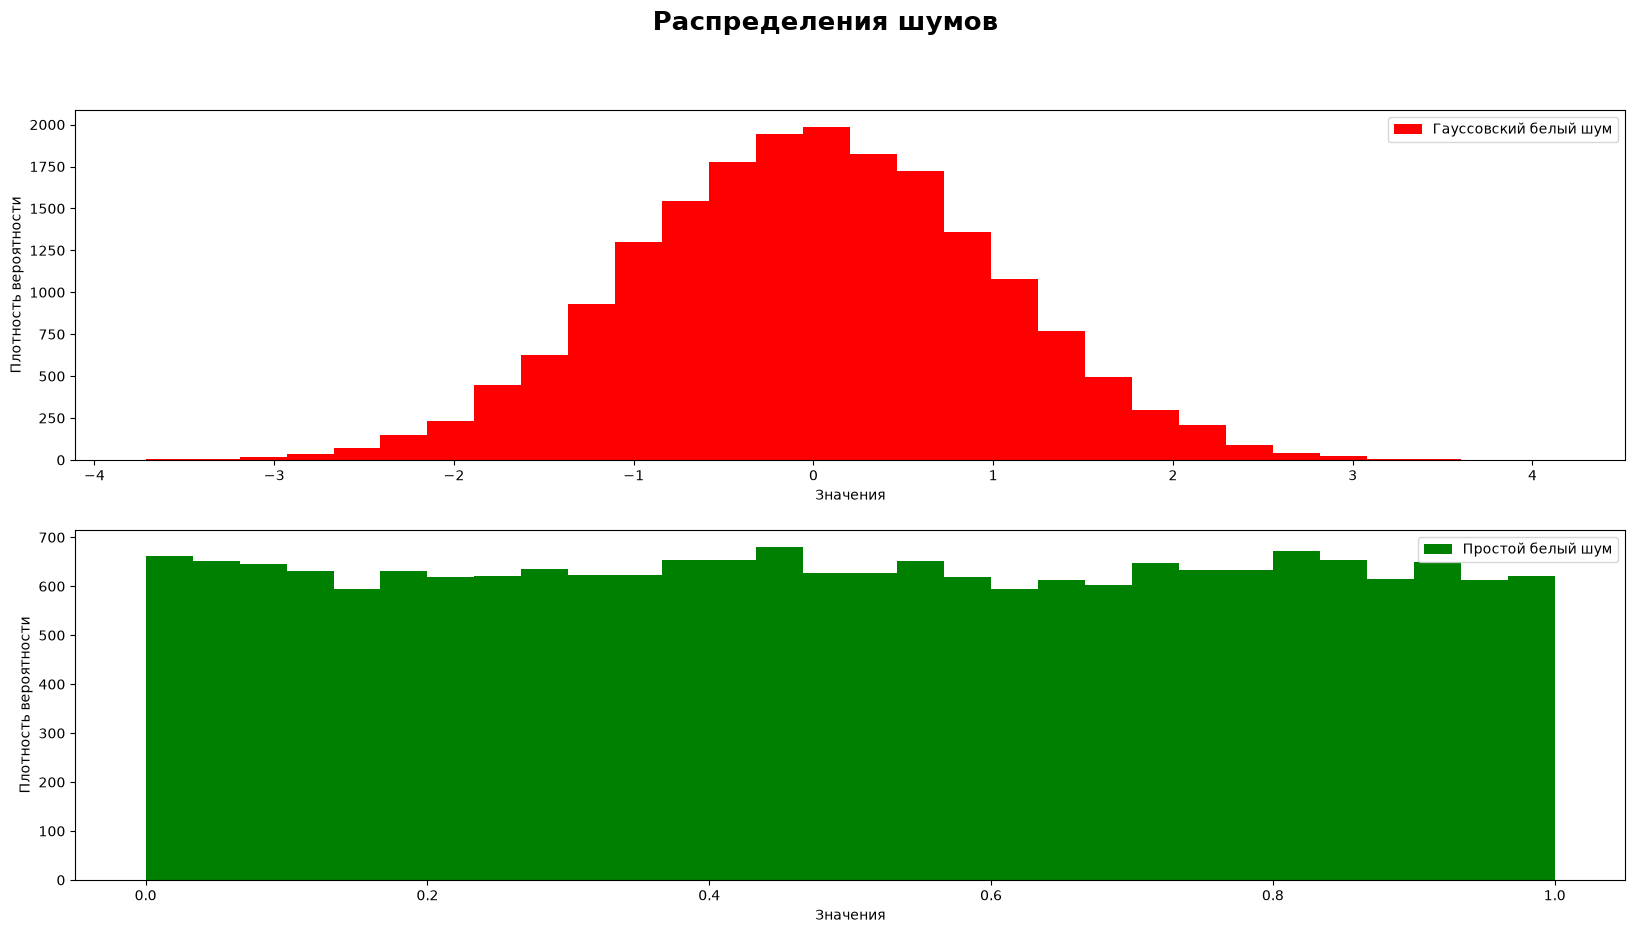

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(20, 10))
fig.suptitle('Распределения шумов', fontsize=19, fontweight='bold')
ax[0].hist(white_noise_g, color="red", bins=30, label="Гауссовский белый шум")
ax[0].set_xlabel('Значения')
ax[0].set_ylabel('Плотность вероятности')
ax[0].legend() 
ax[1].hist(white_noise_simple, color="green", bins=30, label="Простой белый шум")
ax[1].set_xlabel('Значения')
ax[1].set_ylabel('Плотность вероятности')
ax[1].legend()
plt.show()

Коричневый шум

In [9]:
cumsum = np.cumsum(white_noise_g)  
brown_noise = cumsum - np.mean(cumsum)  
scale_coeff =  np.max(np.abs(brown_noise))   

brown_noise = brown_noise / scale_coeff  

print(brown_noise)
print(white_noise_g)

[ 0.50460121  0.49690143  0.49337273 ... -0.39328143 -0.39289888
 -0.3819384 ]
[-0.58145823 -0.70645434 -0.32375766 ... -0.46740496  0.03509953
  1.00562278]


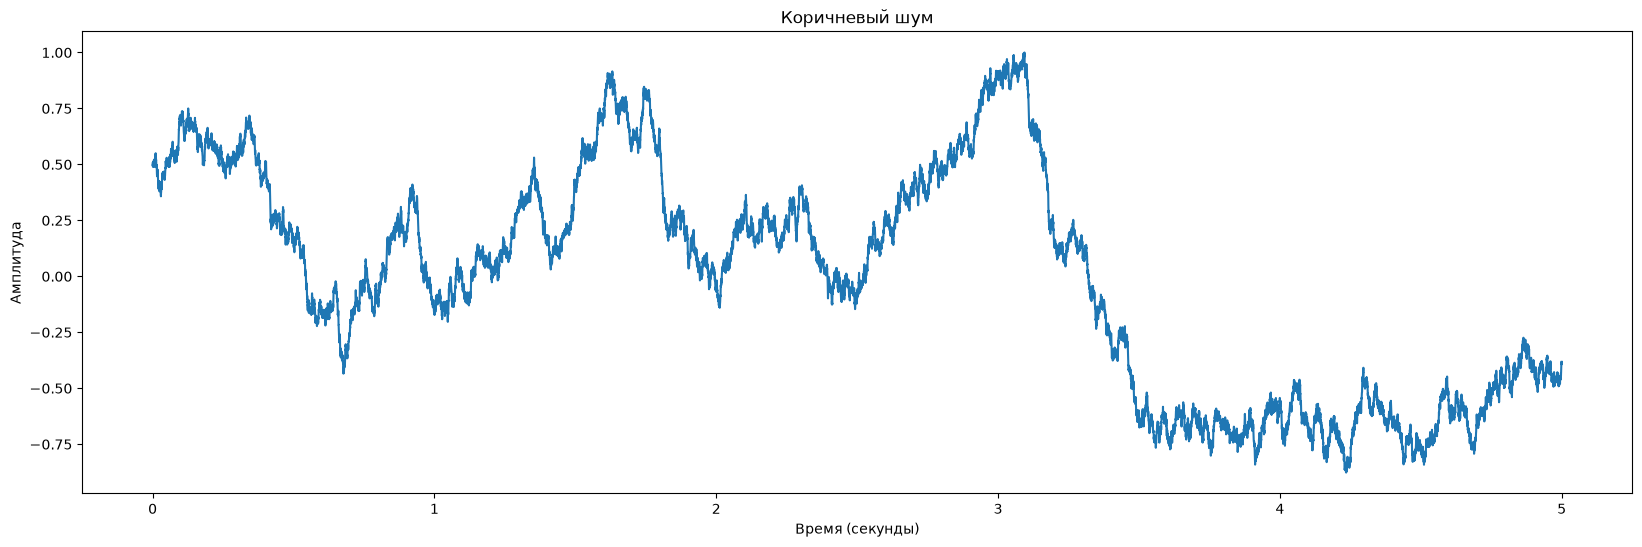

In [10]:
time_axis = np.linspace(0, duration, len(brown_noise)) 

plt.figure(figsize=(20, 6))  

plt.plot(time_axis, brown_noise)

plt.title('Коричневый шум')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')

plt.show()

In [11]:
sd.play(brown_noise, sample_rate)
sd.wait()

Розовый шум

In [12]:
N = len(white_noise_g)
N2 = N//2

print(N)
print(N2)

pink_noise_f = []

for el in white_noise_g:
  
    s = 0
    for k in range(1,N2):
        s += 1/np.sqrt(k) * np.cos(2*np.pi*k*(el-1)/N)
    s *=2
    s = s + 1 + np.cos(np.pi*(el-1))/np.sqrt(N2)

    pink_noise_f.append(s/N)

19000
9500


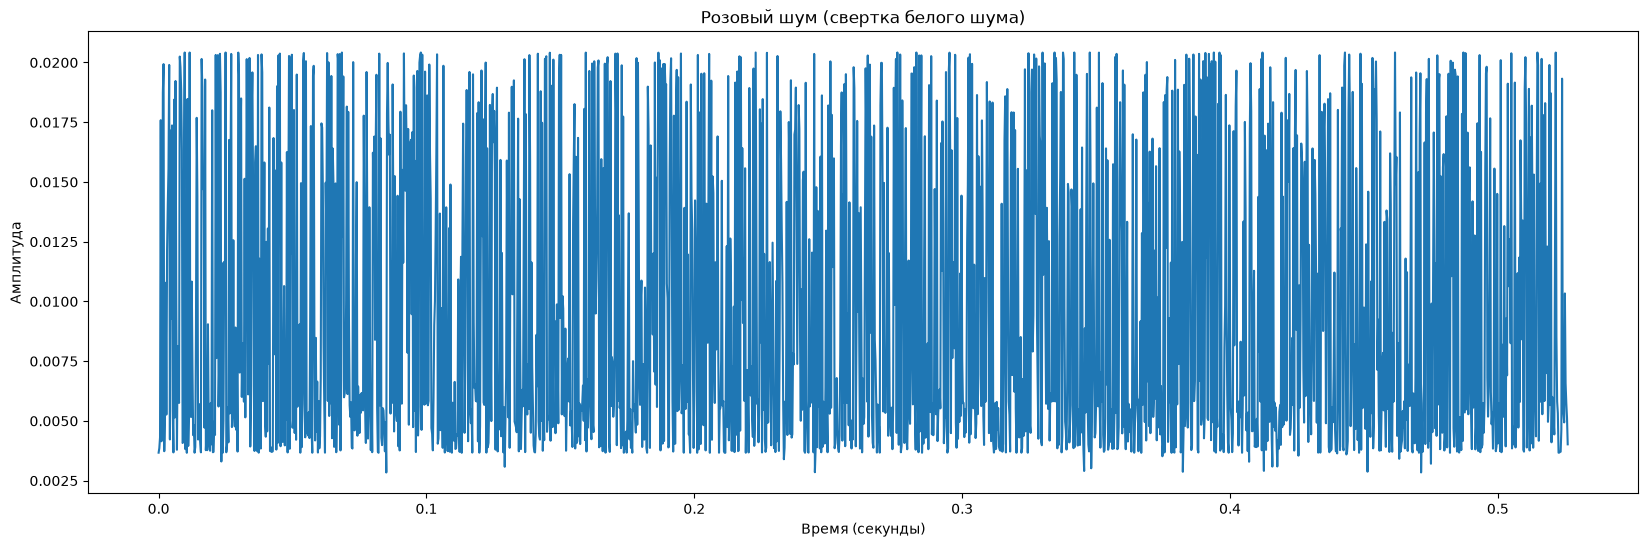

In [13]:
time_axis = np.linspace(0, duration, len(pink_noise_f)) 

plt.figure(figsize=(20, 6))  

plt.plot(time_axis[:2000], pink_noise_f[:2000])

plt.title('Розовый шум (свертка белого шума)')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')

plt.show()

Задание

In [14]:
duration = 5              
sample_rate = 3800        
num_samples = int(duration * sample_rate)

white_noise = np.random.normal(loc=0, scale=1, size=num_samples)

fft_white = np.fft.rfft(white_noise)

freqs = np.fft.rfftfreq(num_samples, d=1/sample_rate)
freqs_safe = np.copy(freqs)
freqs_safe[0] = freqs[1] if len(freqs) > 1 else 1

pink_fft = fft_white / np.sqrt(freqs_safe)
pink_noise = np.real(np.fft.irfft(pink_fft, n=num_samples))

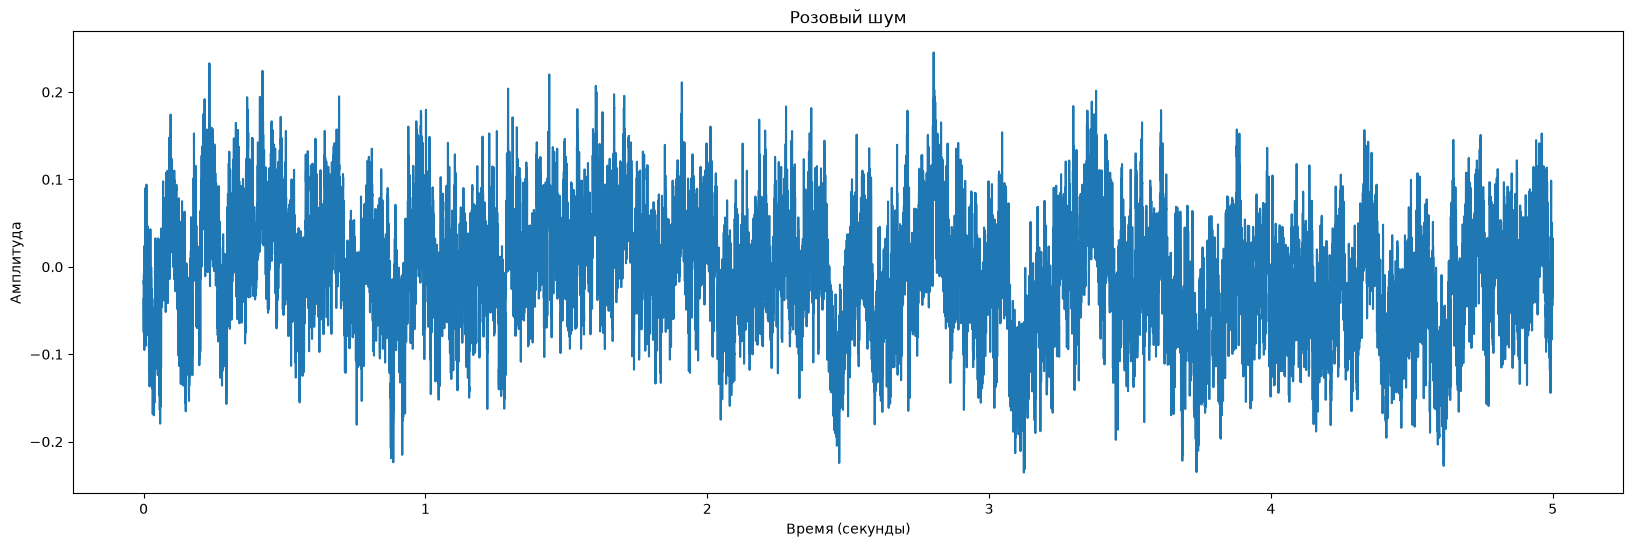

In [15]:
time_axis = np.linspace(0, duration, len(pink_noise)) 

plt.figure(figsize=(20, 6))  
plt.plot(time_axis, pink_noise)
plt.title('Розовый шум')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')
plt.show()

In [16]:
sd.play(pink_noise, sample_rate)
sd.wait()

черный шум

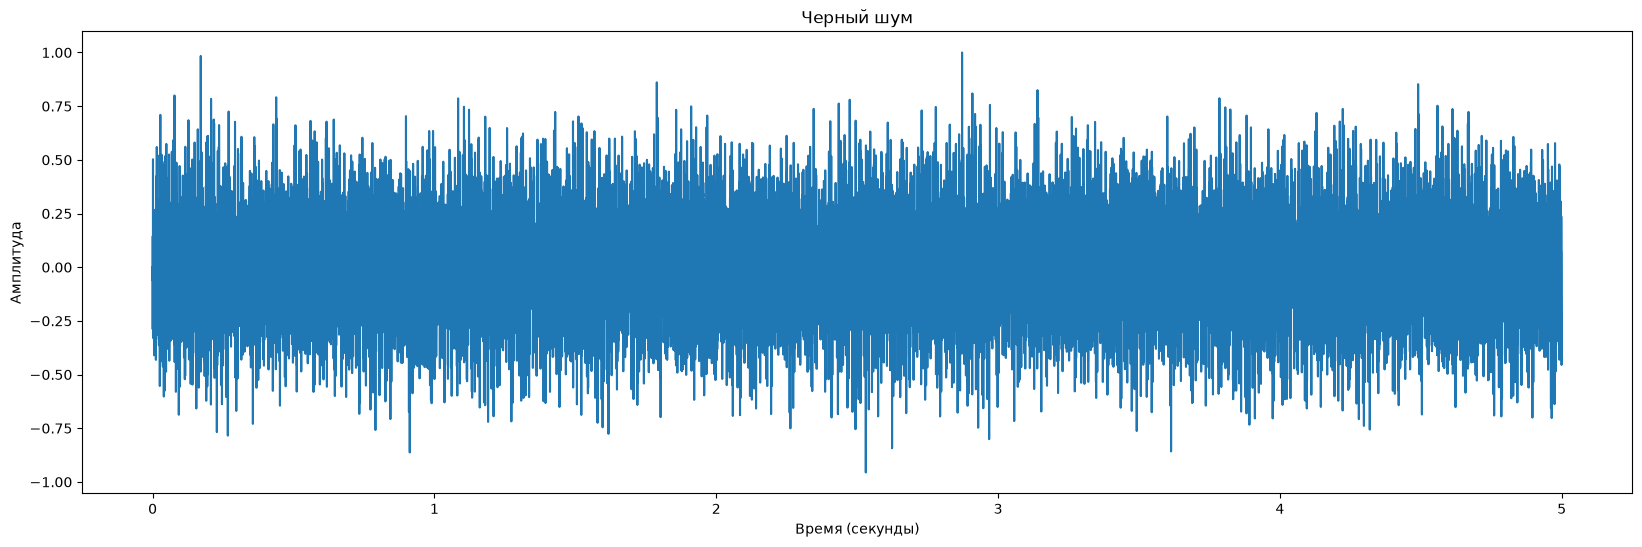

In [17]:

num_samples = int(duration * sample_rate)
freq1 = 20
freq2 = 1500

num_frequencies = 2000  
frequencies = np.linspace(freq1, freq2, num_frequencies) 

black_noise = np.zeros(num_samples)  
time_axis = np.arange(num_samples) / sample_rate   

amplitudes = np.random.normal(0, 1, num_frequencies)  
    
for i in range(num_frequencies):
        black_noise += amplitudes[i] * np.sin(2 * np.pi * frequencies[i] * time_axis)
    
black_noise /= np.max(np.abs(black_noise)) 

time_axis = np.linspace(0, duration, len(black_noise))
plt.figure(figsize=(20, 6))
plt.plot(time_axis, black_noise)
plt.title('Черный шум')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')
plt.show()

In [18]:
sd.play(black_noise, freq2)
sd.wait()

In [19]:
import scipy

kb =  scipy.constants.k
h = scipy.constants.physical_constants['Planck constant'][0]
c = scipy.constants.c

print(kb)
print(h)
print(c)

T = 17*1/np.power(10, 9)  

fs = 44100          
duration = 5.0
coef1 = 2*h/(c*c*T*T*T)
coef2 = h/(kb*T)

num_samples = int(duration * sample_rate)

freq = np.fft.rfftfreq(num_samples, d=1.0 / sample_rate)
freq[0] = freq[1] 

S = coef1 * freq**3 / np.expm1(coef2 * freq) 
S[0] = 0.0

white_noise_g = np.random.normal(loc=0, scale=1, size=num_samples)
X = np.fft.rfft(white_noise_g) * np.sqrt(S * sample_rate / 2.0)
black_noise = np.fft.irfft(X, n=num_samples)

black_noise /= np.max(np.abs(black_noise)) 

1.380649e-23
6.62607015e-34
299792458.0


In [20]:
sd.play(black_noise.astype(np.float32), sample_rate)
sd.wait()

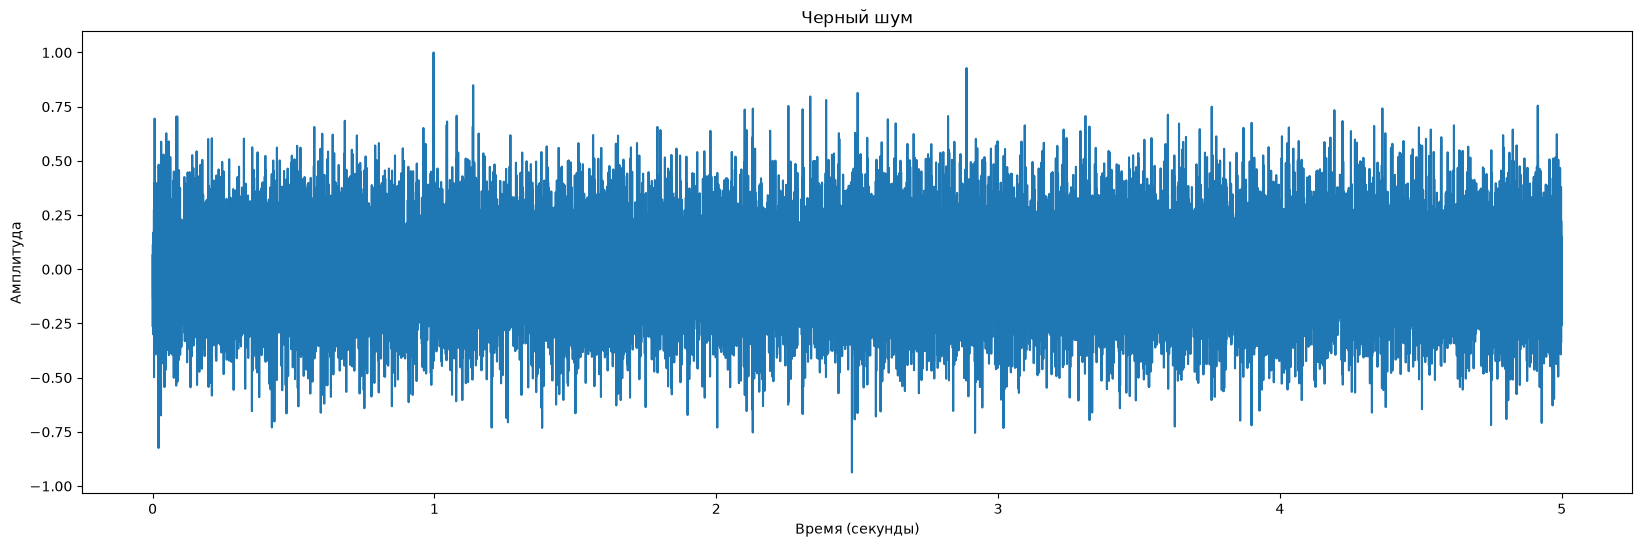

In [21]:
time_axis = np.linspace(0, duration, len(black_noise))
plt.figure(figsize=(20, 6))
plt.plot(time_axis, black_noise)
plt.title('Черный шум')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')
plt.show()

In [22]:
duration = 5  
sample_rate = 3800 

num_points = duration*sample_rate  

time_points = np.linspace(0, duration, num_points)

white_noise_base = np.random.normal(0,1,size=num_points) 

values = 10*np.sin(4*time_points*np.pi) 

values_noise = values + white_noise_base

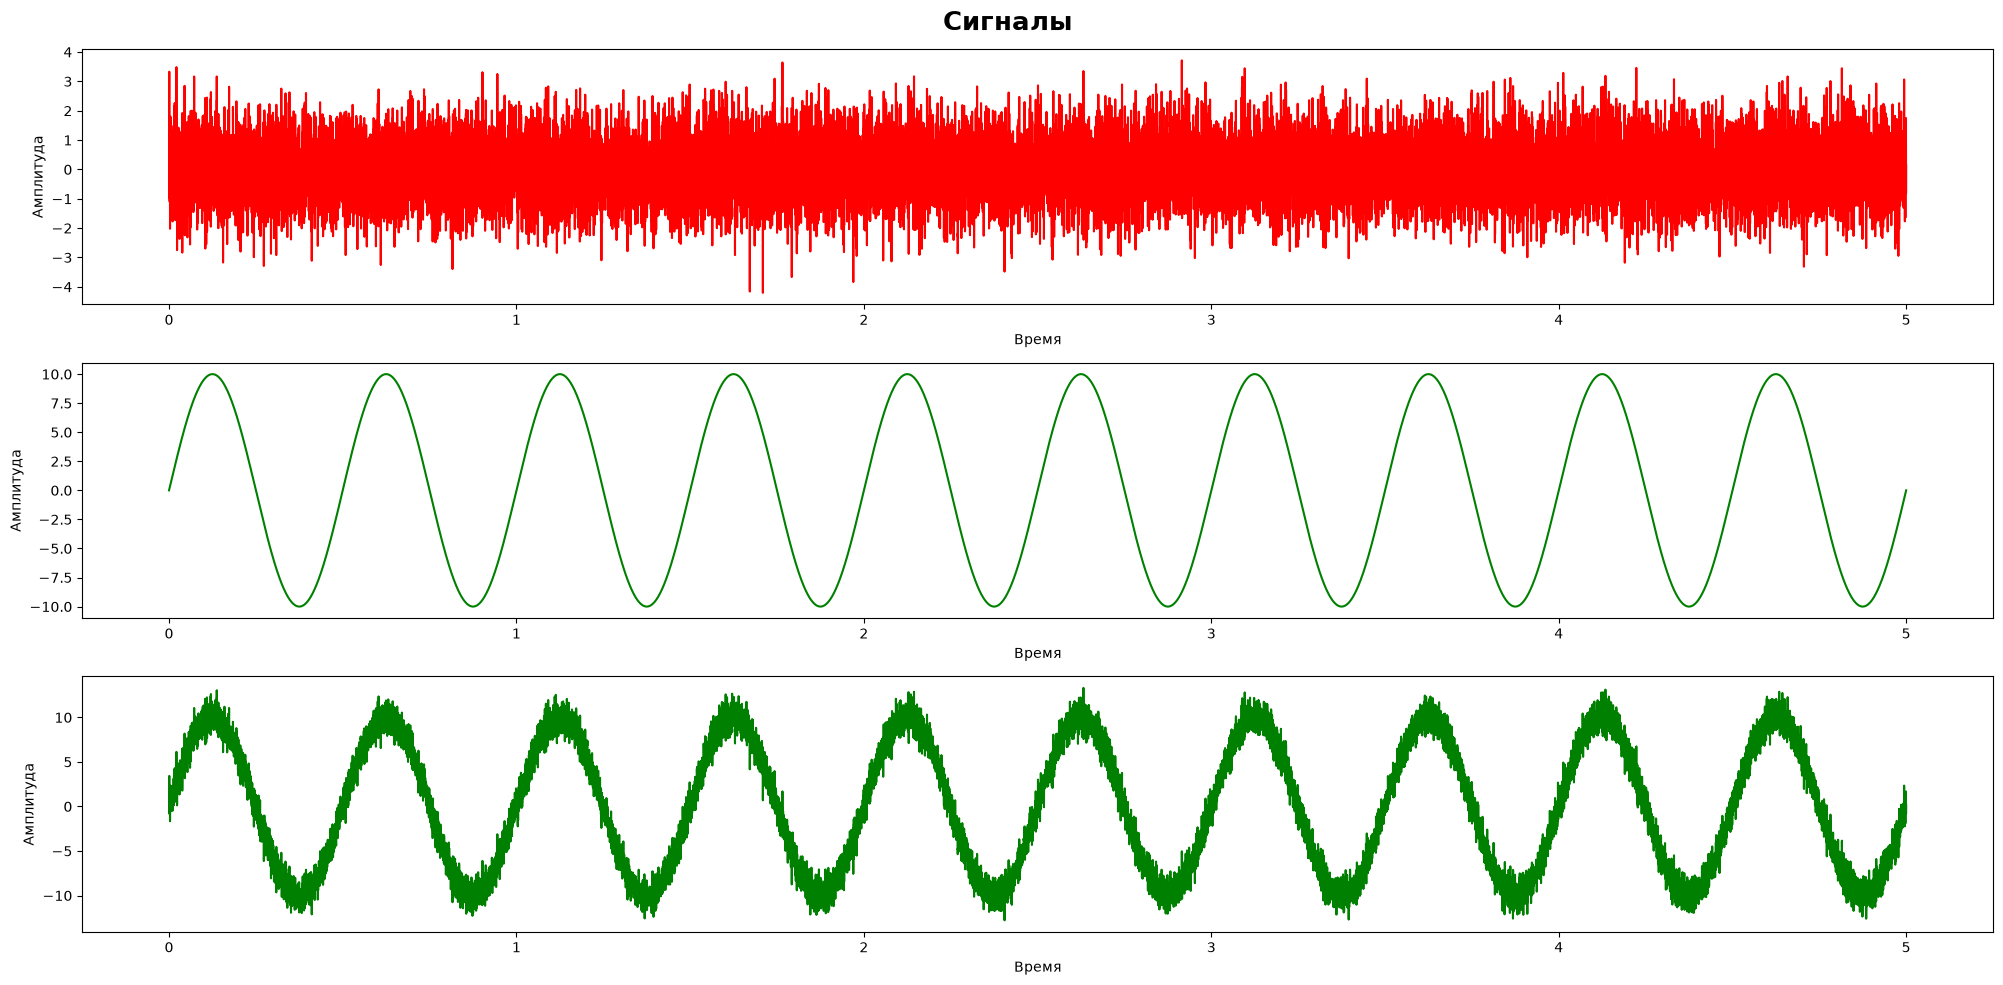

In [23]:

fig, axs = plt.subplots(3, 1, figsize=(20, 10))

fig.suptitle('Сигналы', fontsize=19, fontweight='bold')

labels = ["гауссовский белый шум", "Чистый сигнал", "Зашумленный сигнал"]

c0 = axs[0].plot(time_points, white_noise_base, color="red")
axs[0].set_xlabel('Время')
axs[0].set_ylabel('Амплитуда')

c1 = axs[1].plot(time_points, values, color="green")
axs[1].set_xlabel('Время')
axs[1].set_ylabel('Амплитуда')

c2 = axs[2].plot(time_points, values_noise, color="green")
axs[2].set_xlabel('Время')
axs[2].set_ylabel('Амплитуда')

plt.tight_layout() 
plt.show()


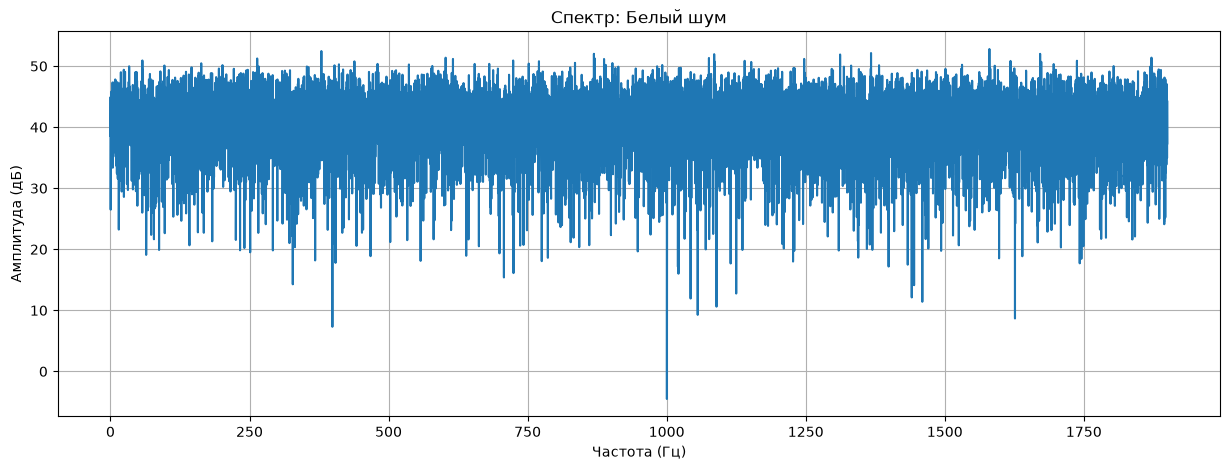

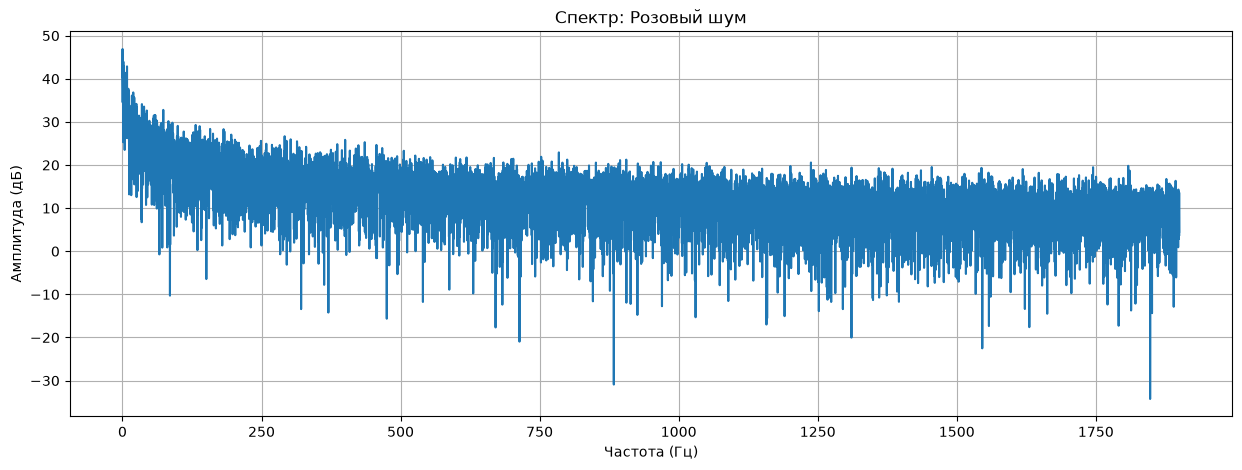

C:\Users\krapa\AppData\Local\Temp\ipykernel_23256\777277692.py:28: RuntimeWarning: divide by zero encountered in log10
  plt.plot(xf, 20 * np.log10(np.abs(yf)))


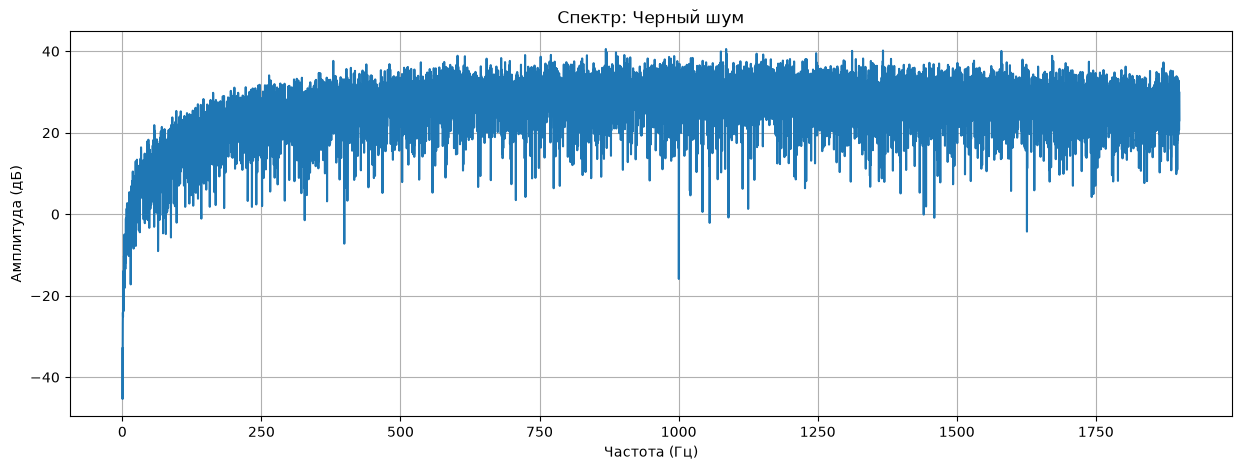

In [24]:
N = len(white_noise_g)
# Быстрое преобразование Фурье
yf = np.fft.rfft(white_noise_g)
xf = np.fft.rfftfreq(N, 1 / sample_rate)
plt.figure(figsize=(15, 5))
plt.plot(xf, 20 * np.log10(np.abs(yf)))
plt.title(f'Спектр: Белый шум')
plt.xlabel('Частота (Гц)')
plt.ylabel('Амплитуда (дБ)')
plt.grid(True)
plt.show()

N = len(pink_noise)
yf = np.fft.rfft(pink_noise)
xf = np.fft.rfftfreq(N, 1 / sample_rate)    
plt.figure(figsize=(15, 5))
plt.plot(xf, 20 * np.log10(np.abs(yf)))
plt.title(f'Спектр: Розовый шум')
plt.xlabel('Частота (Гц)')
plt.ylabel('Амплитуда (дБ)')
plt.grid(True)
plt.show()

N = len(black_noise)
yf = np.fft.rfft(black_noise)
xf = np.fft.rfftfreq(N, 1 / sample_rate)   
plt.figure(figsize=(15, 5))
plt.plot(xf, 20 * np.log10(np.abs(yf)))
plt.title(f'Спектр: Черный шум')
plt.xlabel('Частота (Гц)')
plt.ylabel('Амплитуда (дБ)')
plt.grid(True)
plt.show()